# ThAr ecfw: Chebyshev spectral mixture — order 104

1. Select lines with **screen_fit=False** (database, blend, saturation and usable-window checks remain).
2. Independently optimize each ecfw line; retain those points for comparison.
3. Fit a deterministic Chebyshev 2G IP directly to all selected spectra, with one residual-mixture label per line.
4. Optionally run NUTS initialized at the MAP; show pointwise credible bands for κ₁–κ₅.

The degree is selected manually. The default run is **degree 4, optimization only**.
Individual fits do not run NUTS and do not remove lines. This notebook is independent of the experimental branch's saved fits.
After changing branches or updating the package, restart the kernel before running all cells.

In [1]:
from pathlib import Path
from time import perf_counter
from datetime import datetime
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/gaoesrvip').is_dir())
sys.path.insert(0, str(repo / 'src'))
from gaoesrvip import select_lines, fit, load_result, cumulants
print('Repository:', repo)


Repository: /Users/k_masuda/Dropbox/repos/gaoesrvip


In [2]:
degree = 4
run_nuts = False
warmup, samples, chains, seed = 500, 500, 2, 0
screen_fit = False
blend_guard = 4.0
baseline_degree = 1
tophat = False
min_inlier_probability = 0.5
ci = 0.68
prediction_n_positions = 500
zoom_outliers = True
output_root = repo / 'examples/results/thar_ip_chebyshev_mixture_order104'


## Select the spectra

The central spectrum supplies the catalog and saturation/blend selection. Individual optimization and the joint mixture both use the **ecfw** cutouts below. Screening is opt-in and remains a separate central-spectrum quality cut.

In [3]:
data = select_lines(
    repo / 'data/ThAr20251107_2.center.fits',
    repo / 'data/ecThAr20251107_2.center',
    fit_spectrum=repo / 'data/ThAr20251107_2_ecfw.fits',
    orders=[104], gain=1.935, read_noise=4.0,
    saturation=5000, half_window=7,
    blend_guard=blend_guard, screen_fit=screen_fit,
)
print(f'{len(data[0].x0)} lines; {data[0].mask.sum()} valid pixels')


23 lines; 392 valid pixels


## Fit

The call includes independent least-squares comparison fits, then a regularized spectral initializer and the Chebyshev-mixture MAP. `run_nuts=True` adds joint posterior sampling of the coefficients, local flux/background parameters, and mixture scales/fraction. The IP of each line is always exactly its Chebyshev prediction.

The optimization and sampler use the same priors. The fitted extra residual widths describe model discrepancy in addition to the supplied noise. `P(inlier)` is conditional on the MAP or averaged over NUTS draws; it is not a fixed residual-tolerance criterion across degrees.

In [4]:
started = perf_counter()
chebyshev = fit(
    data, mode='chebyshev', degree=degree,
    model='lab_centered', tophat=tophat, baseline_degree=baseline_degree,
    nuts=run_nuts, warmup=warmup, samples=samples, chains=chains,
    seed=seed, progress=True,
)
fit_seconds = perf_counter() - started
print(f'Total fit time: {fit_seconds:.2f} s')
figures = {}


Order 104: 23 lines; independent LS then degree 4 spectral MAP
  individual 0.50s; MAP 1.80s; 17/23 lines with P(inlier) > 0.5
Total fit time: 2.30 s


In [5]:
curve = chebyshev.orders[0].chebyshev
report = chebyshev.diagnostics[104]
display(pd.DataFrame([report['optimization']]))
print(f"Individual optimization: {report['individual']['seconds']:.2f} s; "
      f'{curve.individual_success.sum()}/{len(curve.individual_success)} successful')
if curve.has_posterior:
    display(pd.DataFrame([report['nuts']]))
    print('Inspect R-hat, ESS, divergences and tree depth before interpreting short-run CIs.')
else:
    print('MAP only: no posterior credible intervals.')
widths = np.median(curve.mixture_samples, axis=0) if curve.has_posterior else curve.mixture_map
display(pd.DataFrame([dict(s_in_percent=100*widths[0], s_out_percent=100*widths[1], epsilon=widths[2])]))
metrics = chebyshev.residual_summary()
display(chebyshev.line_membership.merge(
    metrics[['order', 'line_id', 'rms_observed_peak_percent', 'rms_sigma']],
    on=['order', 'line_id'], validate='one_to_one'))


Individual optimization: 0.50 s; 23/23 successful
MAP only: no posterior credible intervals.


,success,objective,log_likelihood,projected_gradient,numerical_bound_hits,iterations,message,seconds
0,True,-969.878022,973.810263,0.000637,0,2737,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...,1.799475


,s_in_percent,s_out_percent,epsilon
0,1.088772,5.981183,0.240032


,order,line_id,lab_wave,observed_peak,inlier_probability,outlier_probability,individual_success,rms_observed_peak_percent,rms_sigma
0,104,0,5779.8352,2132.518677,9.988037e-01,1.196324e-03,True,2.684994,1.389983
1,104,1,5777.4006,9079.460571,1.000000e+00,1.583665e-09,True,1.021028,1.736578
2,104,2,5773.9463,48503.618896,2.901255e-65,1.000000e+00,True,5.428003,38.927162
3,104,3,5768.1812,96959.124023,1.000000e+00,1.787015e-11,True,0.555574,7.369597
4,104,4,5767.7785,28720.564819,1.000000e+00,3.003464e-11,True,0.602179,2.692821
5,104,5,5763.5290,266702.752319,1.000000e+00,2.167155e-12,True,0.483058,17.910378
6,104,6,5762.7941,12854.204590,6.120084e-29,1.000000e+00,True,4.104428,9.510568
7,104,7,5749.7862,100001.191406,1.000000e+00,9.177043e-09,True,1.237699,11.465619
8,104,8,5749.3883,134645.076172,1.000000e+00,3.055334e-13,True,0.421283,6.787315
9,104,9,5748.7412,283738.376953,1.000000e+00,2.700062e-13,True,0.407195,9.349749


## Each spectral line

Input flux, the Chebyshev 2G components/background, and residuals relative to the **fixed observed peak**. All selected lines are displayed, including broad-component lines. The title gives `P(outlier)` and the full-window residual RMS.

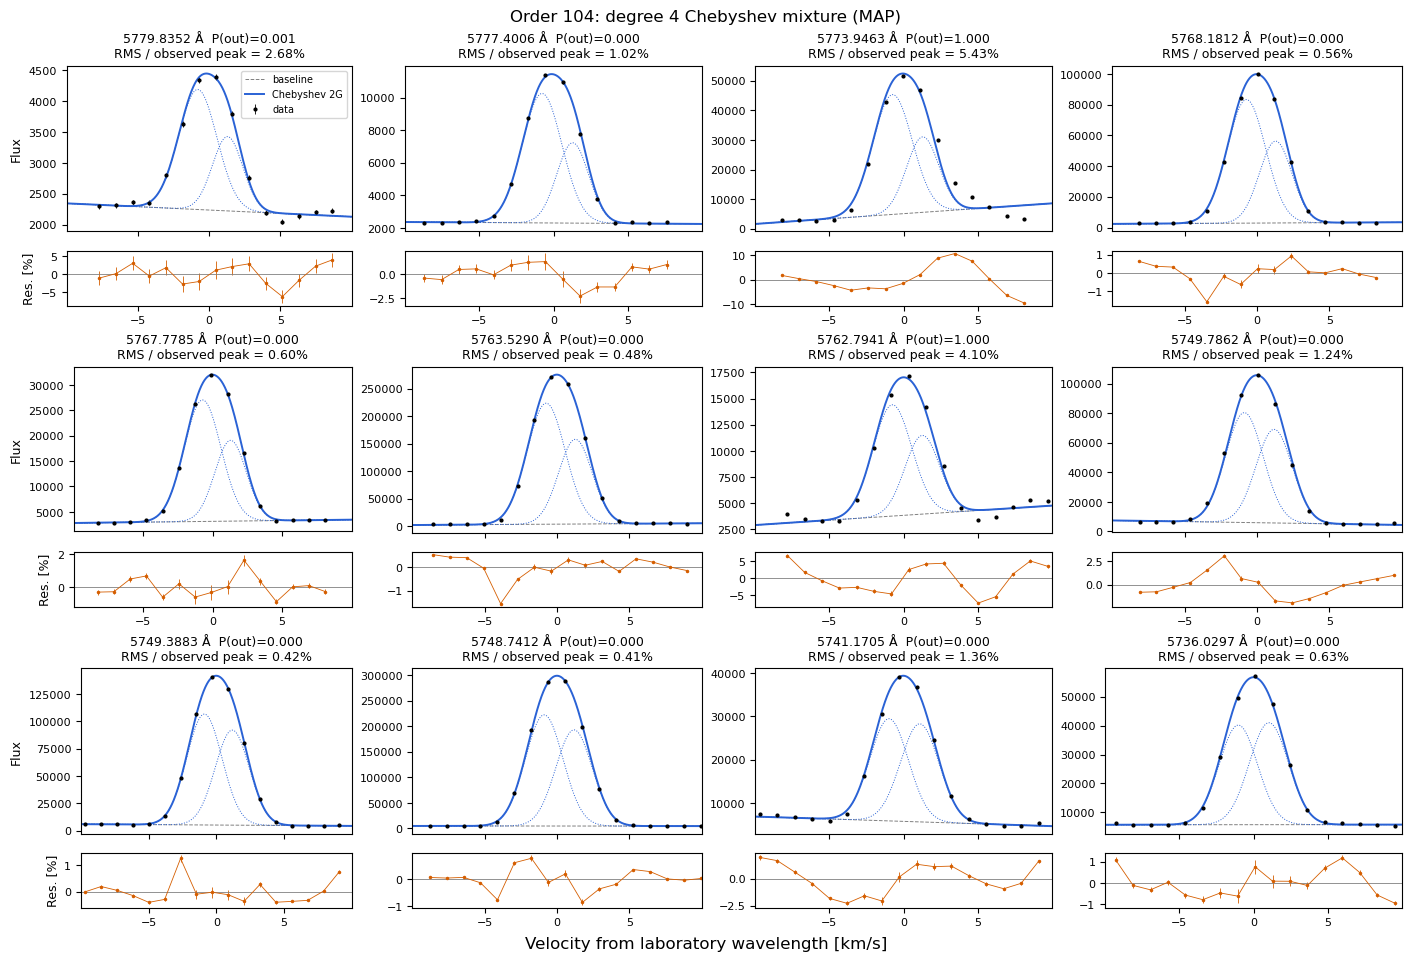

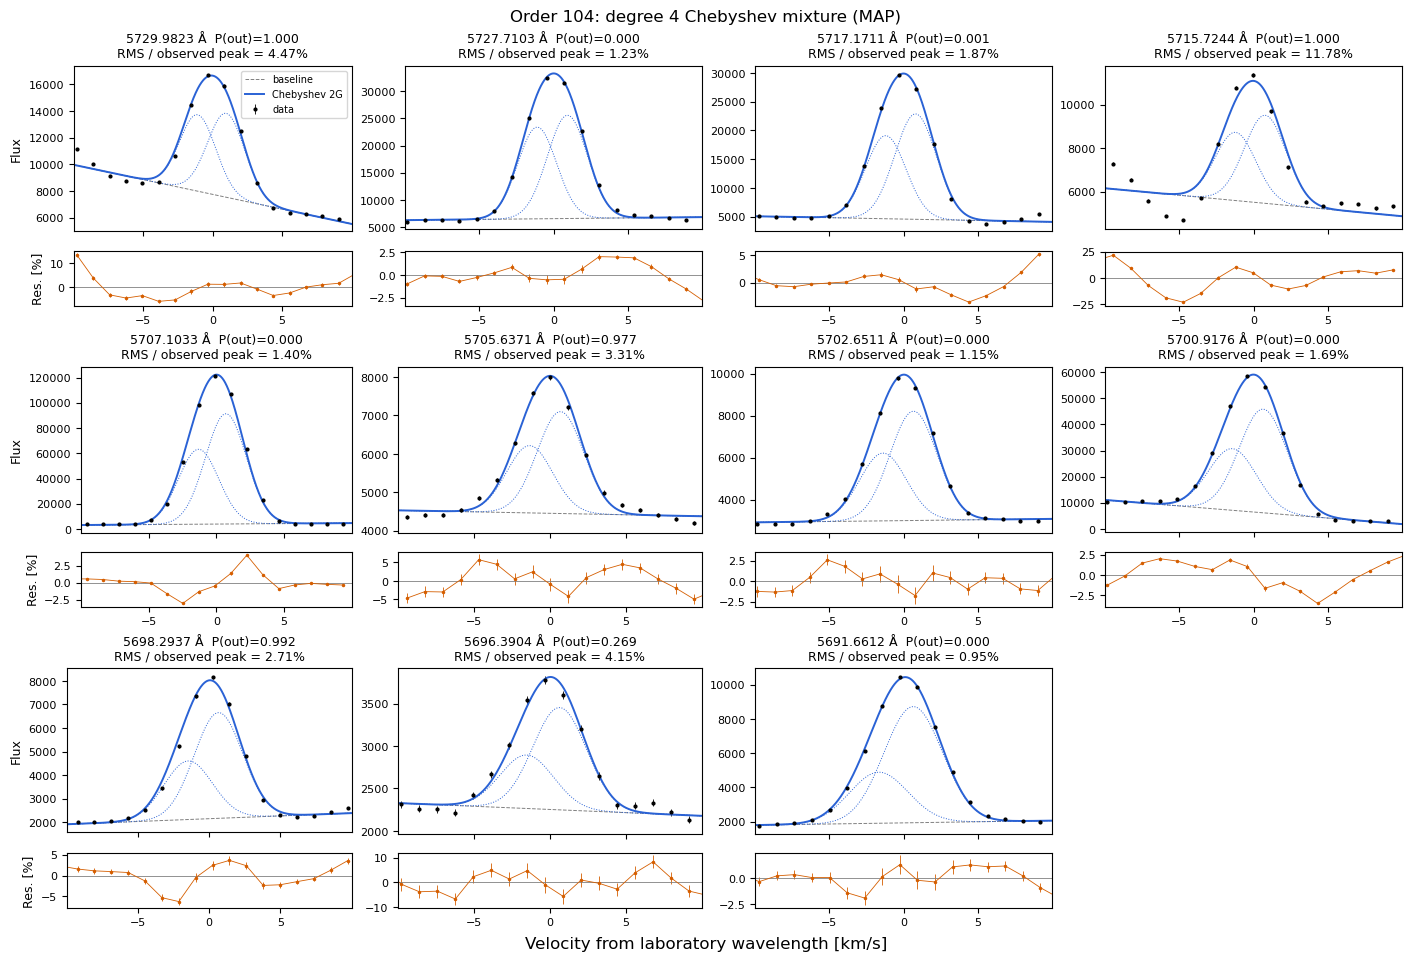

In [6]:
for page, fig in enumerate(chebyshev.plot_lines(include_baseline=True), 1):
    figures[f'lines_order104_{page:03d}'] = fig
    display(fig)
    plt.close(fig)


## Overlay

The threshold only selects which lines are displayed; it does not refit or remove lines from the saved result. Each line has its own wavelength-dependent Chebyshev IP. Positions remain referenced to the laboratory wavelengths.

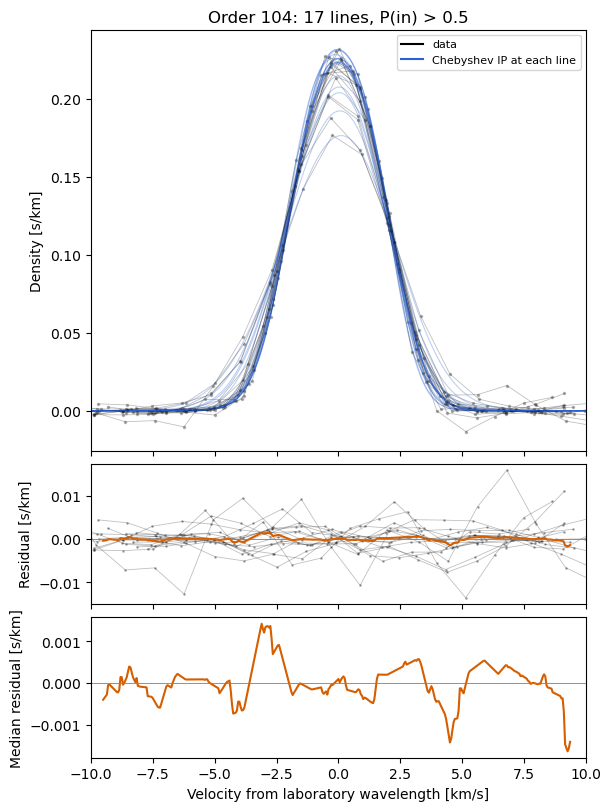

In [7]:
fig = chebyshev.overlay(min_inlier_probability=min_inlier_probability)
figures['overlay_inliers'] = fig
display(fig)
plt.close(fig)


## Cumulants κ₁–κ₅

The smooth line is the MAP curve, or the curve at posterior-median coefficients with NUTS. Bands, when available, are pointwise credible intervals computed from the cumulants of each joint posterior draw. Individual least-squares points have no error bars and are colored by the **spectral** inlier probability. Triangles mark points outside the zoomed view; set `zoom_outliers=False` for the full range.

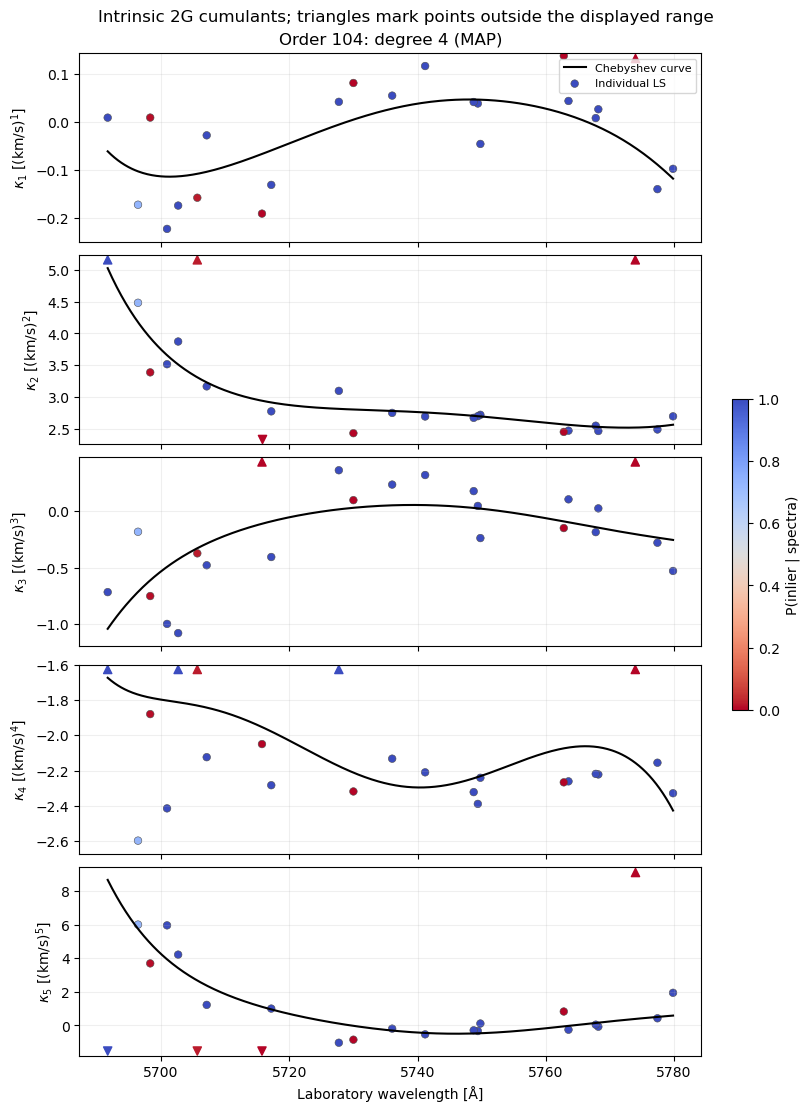

In [8]:
fig = chebyshev.plot_cumulants(ci=ci, n_positions=prediction_n_positions,
                               zoom_outliers=zoom_outliers)
figures['cumulants'] = fig
display(fig)
plt.close(fig)


## Residual RMS and line strength

The full-window RMS and the central ±5 km/s RMS use the same fixed observed peak denominator. Measurement noise is already included in the fit; these unweighted RMS values also contain model mismatch.

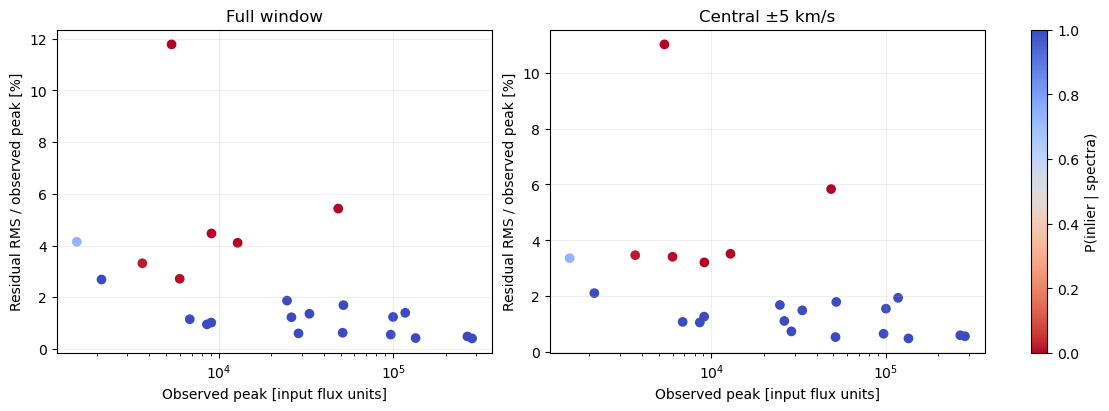

In [9]:
core = chebyshev.residual_summary(velocity_range=(-5., 5.))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, table, title in zip(axes, [metrics, core], ['Full window', 'Central ±5 km/s']):
    points = ax.scatter(table.observed_peak, table.rms_observed_peak_percent,
                        c=table.inlier_probability, cmap='coolwarm_r', vmin=0, vmax=1)
    ax.set(xscale='log', xlabel='Observed peak [input flux units]',
           ylabel='Residual RMS / observed peak [%]', title=title)
    ax.grid(alpha=.2)
fig.colorbar(points, ax=axes, label='P(inlier | spectra)')
figures['rms_vs_peak'] = fig
display(fig)
plt.close(fig)


## Predict on a finer wavelength grid

Grid spacing is independent of the polynomial degree and requires no refit. The returned arrays are `(draw, wavelength, parameter)`; an optimization-only result has one point estimate. Cumulants are intrinsic, before any optional pixel integration.

In [10]:
wave_grid = np.linspace(*curve.domain, prediction_n_positions)
ip_grid = chebyshev.predict_ip(wave_grid, order=104)
kappa_grid = cumulants(ip_grid)
print('IP grid:', ip_grid.shape, 'cumulant grid:', kappa_grid.shape)


IP grid: (1, 500, 5) cumulant grid: (1, 500, 5)


## Save and reload

A new timestamped directory stores both numerical results and these figures. The result includes the individual optimization points and statuses, the MAP, optional NUTS draws, mixture membership, settings, and input cutouts. Replotting a loaded result does not fit again.

In [11]:
output_dir = output_root / f'degree_{degree}' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
chebyshev.save(output_dir, figures=False)
figure_dir = output_dir / 'figures'
figure_dir.mkdir()
for name, fig in figures.items():
    fig.savefig(figure_dir / f'{name}.png', dpi=160, bbox_inches='tight')
np.savez_compressed(output_dir / 'prediction_grid.npz', wavelength=wave_grid,
                    shape=ip_grid, cumulants=kappa_grid)
print('Saved:', output_dir)


Saved: /Users/k_masuda/Dropbox/repos/gaoesrvip/examples/results/thar_ip_chebyshev_mixture_order104/degree_4/20261103_001213_286793


In [12]:
restored = load_result(output_dir)
np.testing.assert_allclose(restored.predict_ip(wave_grid, order=104), ip_grid)
print('Reloaded successfully; no refitting.')
# restored.plot_cumulants()
# restored.overlay(min_inlier_probability=0.5)


Reloaded successfully; no refitting.
